Exercise 7.5

DISCLAIMER: All plotting have been generated with the help of AI tools (Copilot, Claude)

In [3]:
# Import relevant packages
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pysindy as ps
from sklearn.metrics import mean_squared_error

Define Rossler system

In [4]:
def rossler(x_y_z, t0, a, b, c):
    a = a
    b = b
    c = c
    x,y,z = x_y_z
    return [-y-z, x+a*y, b+z*(x-c)]

In [66]:
# Code reused from page 255 from Data-Driven Science and Engineering using the parameters from the exercise
a = 0.2
b = 0.2
c = 14
x0 = (0,0,10)
dt = 0.001
t = np.arange(0,50+dt,dt)

X = odeint(rossler, x0, t, rtol = 10**(-12), atol = 10**(-12)*np.ones_like(x0), args = (a,b,c))
x, y, z = X.T
print(X.shape)
print(t.shape)

(50001, 3)
(50001,)


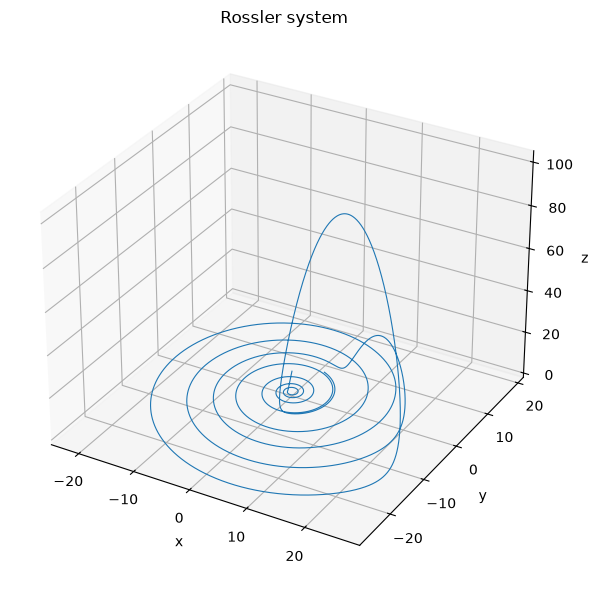

In [67]:
# Visualizing the chaotic Rossler system
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z, linewidth=0.8)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Rossler system")

plt.tight_layout()
plt.show()

In [ ]:
# Now a model is created based on the pysindy library
differentiation_method = ps.FiniteDifference(order=2) # Finite difference method for differentiation
feature_library = ps.PolynomialLibrary(degree=3) # Using the polynomial library with a polynomial degree up to 3
optimizer = ps.STLSQ(threshold=0.1) # Threshold of 0.1

model = ps.SINDy(
    differentiation_method=differentiation_method,
    feature_library=feature_library,
    optimizer=optimizer,
)

In [ ]:
# The model is fitted based on the data
feature_names=["x", "y", "z"]
model.fit(X, t=t, feature_names=feature_names)
model.print()

(x)' = -1.000 y + -1.000 z
(y)' =  1.000 x +  0.200 y
(z)' =  0.200 1 + -14.000 z +  1.000 x z


The fitted model matches exactly the Rossler system

In the aboive example the sparsifying threshold is on 0.1, which means that all coefficients >=0.1 will be eliminated and all other coefficients will be updated until only >0.1 coefficients remain. This is a quite good threshold on this system as the lowest true coeffcient is 0.2 in the Rossler system. This threshold will however eliminate most/all coefficients created from noise in the system (which is not present here, but will be present later)

First it is discovered what the trajectory lengths does to the fitting of the model using a time final of 0.5, 1, 2, 5, 10, 20 and 50 with a dt = 0.001 for all cases

In [73]:
lengths_T = [0.5, 1, 2, 5, 10, 20, 50]  # training time spans

model_coefficients = []

for val in lengths_T:
    # Find the indices where t <= val
    indices = np.where(t <= val)[0]
    
     # Use the corresponding time array
    t_train = t[indices]
    
    X_train = odeint(rossler, x0, t_train, rtol = 10**(-12), atol = 10**(-12)*np.ones_like(x0), args = (a,b,c))
    x, y, z = X_train.T
    model_coefficients.append([x,y,z])
    # The model is fitted based on the data
    feature_names=["x", "y", "z"]
    model.fit(X_train, t=t_train, feature_names=feature_names)
    print(f"\nTraining time: {val}")
    model.print()


Training time: 0.5
(x)' = -0.977 y + -1.000 z +  0.069 x y +  0.053 x^2 y
(y)' =  0.924 x + -0.196 x^2
(z)' = -0.457 1 +  0.430 x + -1.654 y + -10.977 z +  0.998 x^2 + -0.834 x y +  7.049 x z + -0.013 y z + -0.296 z^2 + -1.193 x^3 +  1.032 x^2 y +  2.924 x^2 z + -0.232 x y z + -0.204 x z^2 +  0.183 y z^2

Training time: 1
(x)' = -0.997 y + -1.000 z +  0.005 x y + -0.001 y^2 + -0.005 y^3
(y)' =  1.003 x + -0.270 x y +  0.226 y^3
(z)' = -0.048 1 + -0.231 y + -11.187 z +  1.115 x^2 + -0.168 x y +  6.913 x z + -0.030 y^2 +  0.217 y z + -0.279 z^2 +  0.883 x^3 +  0.135 x^2 y +  2.826 x^2 z + -0.298 x y z + -0.204 x z^2 + -0.159 y^3 +  0.245 y z^2

Training time: 2
(x)' = -1.000 y + -1.000 z
(y)' = -0.165 1 +  0.487 x + -0.240 x y +  0.607 x^3 +  0.402 x y^2
(z)' = -0.072 1 +  0.057 y + -11.438 z +  0.395 x^2 +  0.075 x y +  6.443 x z +  0.466 y^2 +  0.309 y z + -0.253 z^2 + -0.230 x^3 +  2.744 x^2 z + -0.207 x y^2 + -0.074 x y z + -0.193 x z^2 +  0.053 y^3 +  0.205 y z^2

Training time: 5


Here its seen that if not enough data is provided (long enough trajectory lenght) the model does not have enough time to fit the model properly. This is due to the trajectory havent "reach" the systematic cyclic behaviour that can be traced by the model. At t = 10 the model is true, but this is possibly also only due to the sparsity threshold removing small coefficients as discussed earlier forcing the model towards the true model. Below is a plot of the trajectories at t = [5,10,50], where it can be seen that first at t = 50 the full trajectory has been reached. This however shows that a good fit between threshold and trajectory length can minimize the time needed for simulation without compromising on the model fit. 

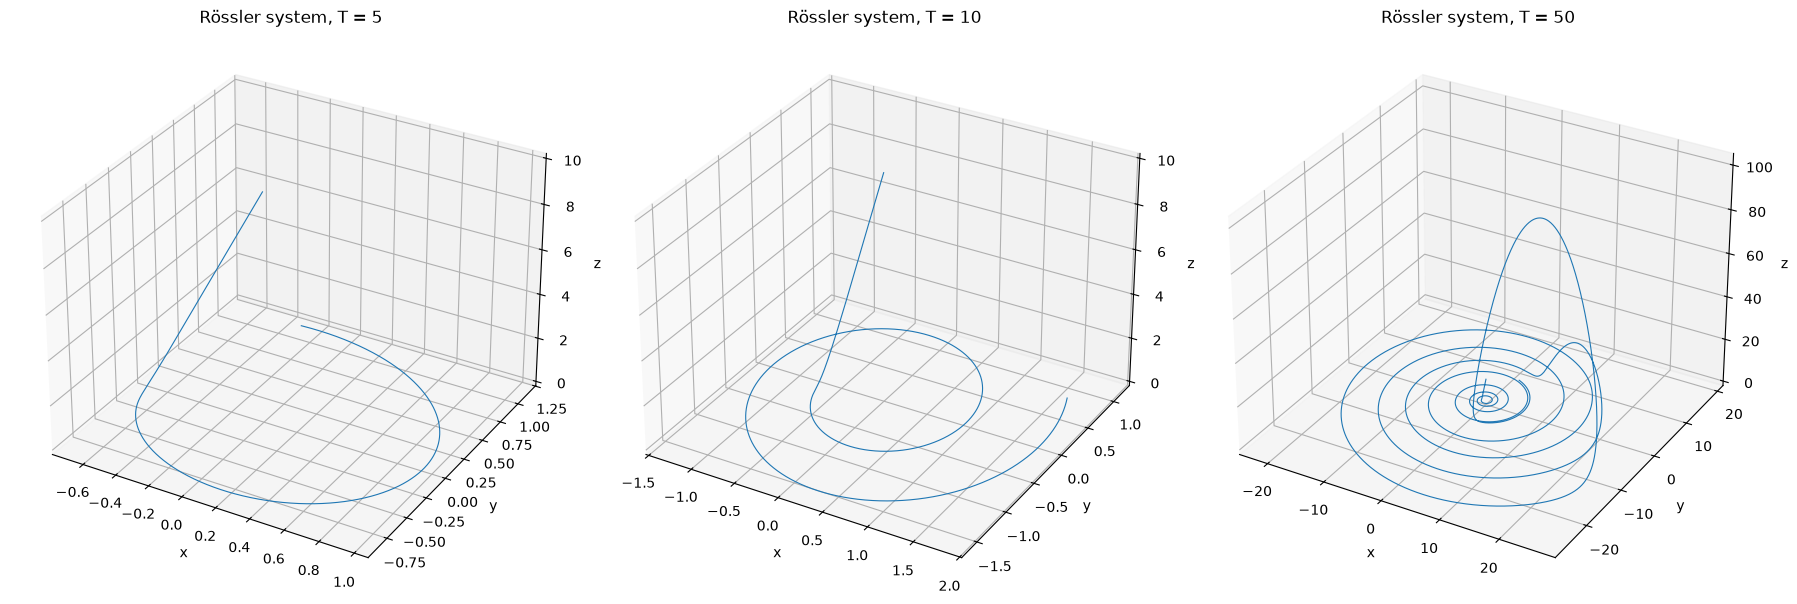

In [74]:
fig = plt.figure(figsize=(18, 6))

for k, val in enumerate([5, 10, 50]):
    idx = lengths_T.index(val)
    x_p, y_p, z_p = model_coefficients[idx]

    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    ax.plot(x_p, y_p, z_p, linewidth=0.8)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_title(f"Rössler system, T = {val}")

plt.tight_layout()
plt.show()

Now its time to explore some different sparsifying thresholds. Here a sparsifying threshold from 0 -> 1 will be explored on noisy data

In [ ]:
# Creating a test dataset from a different initial condition
np.random.seed(23)
x0_test = (1, -1, 5)
t_test = np.arange(0, 10 + dt, dt)
x_test = odeint(rossler, x0_test, t_test, rtol=1e-12,
                atol=1e-12 * np.ones(3), args=(a, b, c))

# Creating a noisy training dataset
rmse = np.sqrt(mean_squared_error(X, np.zeros_like(X)))
noise_level = 0.001
x_noisy = X + np.random.normal(0, rmse * noise_level, X.shape)

In [46]:
# True derivatives evaluated on the test data
dx_true = np.array([rossler(xi, 0, a, b, c) for xi in x_test])

threshold_scan = np.linspace(0, 1.0, 10)
mse = []
model_list = []
for threshold in threshold_scan:
    model = ps.SINDy(
        differentiation_method=differentiation_method,
        feature_library=feature_library,
        optimizer=ps.STLSQ(threshold=threshold),
    )
    model.fit(x_noisy, t=t, feature_names=feature_names)
    model_list.append(model)
    dx_pred = model.predict(x_test)   # model's dx/dt at the test points
    mse.append(mean_squared_error(dx_true, dx_pred))

/opt/homebrew/Caskroom/miniforge/base/envs/ml/lib/python3.11/site-packages/pysindy/optimizers/stlsq.py:234: UserWarning: Sparsity parameter is too big (1.0) and eliminated all coefficients
  warnings.warn(
/opt/homebrew/Caskroom/miniforge/base/envs/ml/lib/python3.11/site-packages/pysindy/optimizers/stlsq.py:224: UserWarning: Sparsity parameter is too big (1.0) and eliminated all coefficients
  warnings.warn(


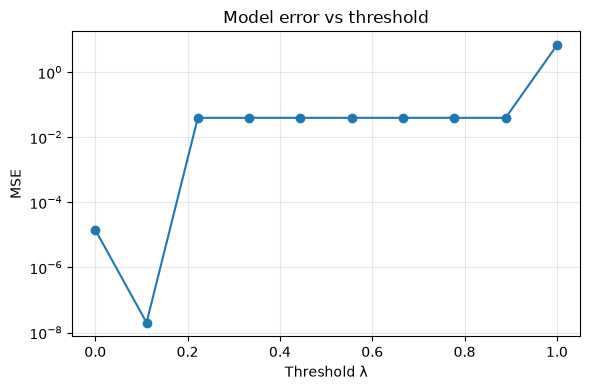

In [ ]:
# Plotting the mean squared error between the of the derivatives of the true Rossler system 
# and the predicted Rossler system based on the models created
plt.figure(figsize=(6, 4))
plt.plot(threshold_scan, mse, "o-")
plt.yscale("log")
plt.xlabel("Threshold λ")
plt.ylabel("MSE")
plt.title("Model error vs threshold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

On the above graph it can be seen that for a system with noise there is a difference between the true system and the Sindy predicted system if no threshold is used. However, with a threshold of 0.1 all the noisy terms is filtered away and only the "True" terms are left. As discussed earlier a threshold of above >=2 is too high as a term in the Rossler system has a coefficient of 0.2 and the True system can therefore never be found. Is is demonstrated below for the first 3 models:

In [47]:
for i in range(3):
    print(f"Model {i+1}:")
    model_list[i].print()

Model 1:
(x)' = -1.000 y + -0.996 z + -0.004 x z
(y)' = -0.002 1 +  1.000 x +  0.200 y +  0.022 z + -0.005 x z +  0.002 y z
(z)' =  0.196 1 + -13.976 z +  0.983 x z +  0.003 y z +  0.001 z^2 +  0.001 x^2 z
Model 2:
(x)' = -1.000 y + -1.000 z
(y)' =  1.000 x +  0.200 y
(z)' =  0.200 1 + -13.999 z +  1.000 x z
Model 3:
(x)' = -1.000 y + -1.000 z
(y)' =  0.961 x
(z)' = -13.995 z +  1.000 x z


Here it can be seen that the first model has way to many terms (from noise), the second is (almost) true to the Rosller system, however, the third have had too many terms removed from the too high sparsity threshold. 